In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("Dataset Information:")
df.info()

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())


Dataset shape: (4757, 23)


,market,country_code,founded_year,funding_total_usd,funding_rounds,unclassified_funding,seed,angel,equity_crowdfunding,convertible_note,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,status
0,News,USA,2012,1750000.0,1,0.0,1750000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,Advertising,ARG,2007,4912393.0,1,4912393.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,Curated Web,USA,2010,2535000.0,2,0.0,15000.0,0.0,0.0,0.0,...,0.0,2520000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,Analytics,USA,2011,1250000.0,2,500000.0,750000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,Curated Web,USA,2009,50000.0,1,0.0,50000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4757 entries, 0 to 4756
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   market                4757 non-null   str    
 1   country_code          4757 non-null   str    
 2   founded_year          4757 non-null   int64  
 3   funding_total_usd     4757 non-null   float64
 4   funding_rounds        4757 non-null   int64  
 5   unclassified_funding  4757 non-null   float64
 6   seed                  4757 non-null   float64
 7   angel                 4757 non-null   float64
 8   equity_crowdfunding   4757 non-null   float64
 9   convertible_note      4757 non-null   float64
 10  debt_financing        4757 non-null   float64
 11  grant                 4757 non-null   float64
 12  private_equity        4757 non-null   float64
 13  product_crowdfunding  4757 non-null   float64
 14  round_A               4757 non-null   float64
 15  round_B    

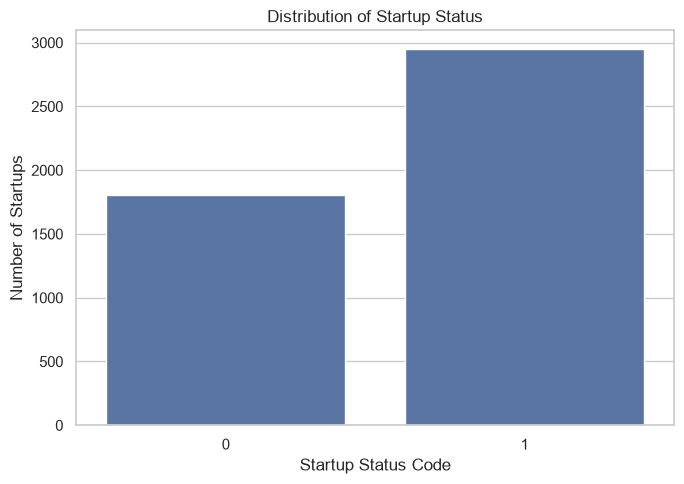

In [31]:
status_counts = df["status"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(x=status_counts.index.astype(str), y=status_counts.values)

plt.title("Distribution of Startup Status")
plt.xlabel("Startup Status Code")
plt.ylabel("Number of Startups")
plt.tight_layout()
plt.show()

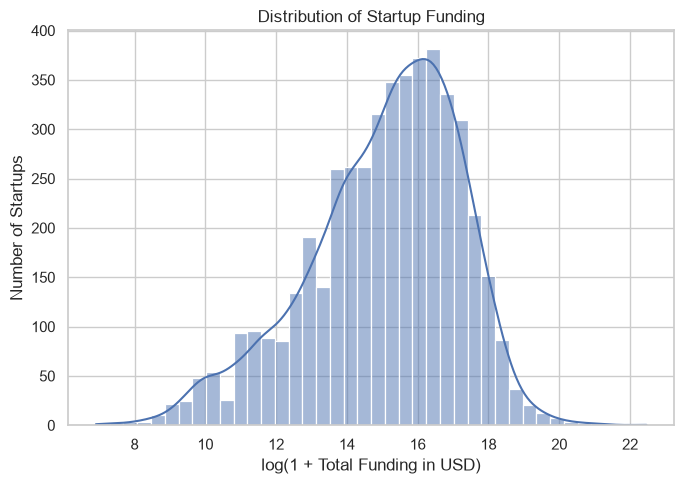

In [32]:
funding = df["funding_total_usd"].dropna()
funding = funding[funding >= 0]

plt.figure(figsize=(7, 5))
sns.histplot(np.log1p(funding), bins=40, kde=True)

plt.title("Distribution of Startup Funding")
plt.xlabel("log(1 + Total Funding in USD)")
plt.ylabel("Number of Startups")
plt.tight_layout()
plt.show()

Average Funding by Status:
status
0    9.073167e+06
1    2.403193e+07
Name: funding_total_usd, dtype: float64


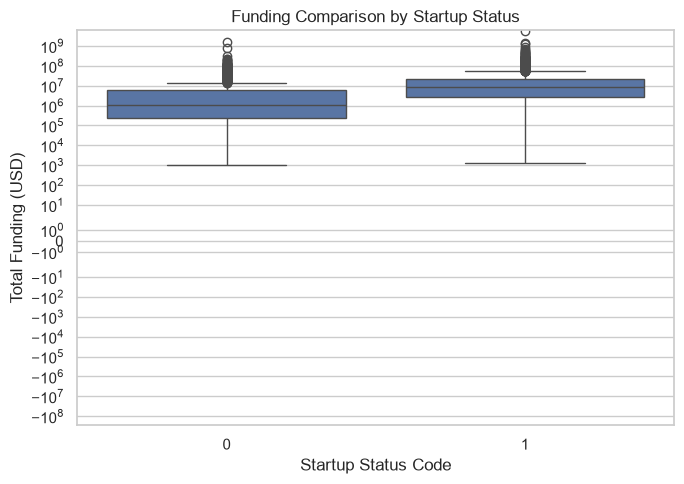

In [33]:
print("Average Funding by Status:")
print(df.groupby("status")["funding_total_usd"].mean())

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="status", y="funding_total_usd")

plt.yscale("symlog")
plt.title("Funding Comparison by Startup Status")
plt.xlabel("Startup Status Code")
plt.ylabel("Total Funding (USD)")
plt.tight_layout()
plt.show()